# 02 · Firmware experiment design (experimental layer)

There is no public dataset of real hardware readings tagged with real firmware releases, so this layer is constructed
on purpose and clearly labelled. Every synthetic choice lives in `src/experiment_design.py` and is reproducible from a seed.

**Fleet.** Each real IMS bearing history is cut into non-overlapping 240-snapshot (40 h) windows, and each window is one
*device*. That gives 152 devices whose vibration is real, including natural wear and four run-to-failure units.

**Design.** A staged rollout with a concurrent control arm:
* Intervals 0-119: every device runs **v1.0.0**.
* Interval 120: about 60% of devices (the *treatment* arm) receive **v2.0.0**. The *control* arm stays on v1.0.0.
* Randomisation is stratified by hardware revision, test rig and end-of-life status, so bearing wear is balanced across arms.

This supports **difference-in-differences**: each device is compared with itself, and the control arm removes drift that
affects the whole fleet (bearing wear, latency incidents).

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
P = ROOT / "data" / "processed"

In [2]:
from src.experiment_design import FIRMWARE_RELEASES, COLUMN_ORIGIN
FIRMWARE_RELEASES

,firmware_version,release_date,status,notes
0,1.0.0,2025-06-02,stable,Baseline production firmware.
1,2.0.0,2026-01-05,staged rollout,"New DSP filter on vibration channel, async tel..."


In [3]:
devices = pd.read_csv(ROOT / "data/firmware_metadata/devices.csv")
print(len(devices), "devices")
pd.crosstab([devices.hw_revision, devices.contains_end_of_life], devices.group, margins=True)

152 devices


group                             control  treatment  All
hw_revision contains_end_of_life                         
A           False                      42         64  106
            True                        1          2    3
B           False                      17         25   42
            True                        0          1    1
All                                    60         92  152

In [4]:
pd.crosstab(devices.source_test, devices.group)

group,control,treatment
source_test,,
test1,13,19
test2,6,10
test3,41,63


### Injected v2.0 effects (ground truth, used only for validation)
| Area | Rev A | Rev B | Mechanism |
|---|---|---|---|
| Vibration DSP filter | EMA α=0.5 | EMA α=0.5 | smoother readings, real signal preserved in `real_*` |
| RMS calibration | ×1.00 | ×1.06 | calibration-table bug on rev B |
| Response time | ×0.88 | ×1.22 | async stack helps A; new I2C driver blocks on B |
| Firmware errors (Poisson) | ×0.75 | ×2.2 | I2C bus timeouts on B |
| Reboot probability / interval | 0.001 | 0.008 | watchdog resets on B |

Hardware faults are derived only from the **real** bearing signal, so firmware cannot cause or hide them. Monitoring
alarms use the reading *as reported by firmware*, so the new filter can legitimately change alarm behaviour.

In [5]:
print(json.dumps(COLUMN_ORIGIN, indent=1))

{
 "real (NASA IMS)": [
  "source_timestamp",
  "real_rms",
  "real_kurtosis",
  "real_peak",
  "hardware_fault"
 ],
 "real (NAB ec2_request_latency) + experimental firmware effect": [
  "response_time_ms"
 ],
 "real IMS signal + experimental firmware filter/calibration": [
  "vib_rms",
  "vib_kurtosis",
  "vib_peak",
  "vibration_alarm"
 ],
 "experimental": [
  "device_id",
  "timestamp",
  "firmware_version",
  "period",
  "group",
  "hw_revision",
  "region",
  "fw_error_count",
  "reboot",
  "downtime_min",
  "uptime_pct"
 ]
}


In [6]:
tel = pd.read_parquet(P / "telemetry.parquet")
tel.head()

,device_id,interval_idx,timestamp,firmware_version,period,group,hw_revision,region,source_timestamp,real_rms,real_kurtosis,real_peak,vib_rms,vib_kurtosis,vib_peak,response_time_ms,fw_error_count,vibration_alarm,hardware_fault,reboot,downtime_min,uptime_pct
0,DEV-0001,0,2026-01-05 00:00:00,1.0.0,pre,treatment,A,EU-West,2003-10-22 12:06:24,0.1246,4.0692,0.720,0.1246,4.0692,0.720,51.8134,0,False,False,False,0.0,100.0
1,DEV-0001,1,2026-01-05 00:10:00,1.0.0,pre,treatment,A,EU-West,2003-10-22 12:09:13,0.1238,4.1616,0.654,0.1238,4.1616,0.654,46.2485,0,False,False,False,0.0,100.0
2,DEV-0001,2,2026-01-05 00:20:00,1.0.0,pre,treatment,A,EU-West,2003-10-22 12:14:13,0.1252,3.9863,0.623,0.1252,3.9863,0.623,49.0117,0,False,False,False,0.0,100.0
3,DEV-0001,3,2026-01-05 00:30:00,1.0.0,pre,treatment,A,EU-West,2003-10-22 12:19:13,0.1252,4.0343,0.598,0.1252,4.0343,0.598,49.7094,0,False,False,False,0.0,100.0
4,DEV-0001,4,2026-01-05 00:40:00,1.0.0,pre,treatment,A,EU-West,2003-10-22 12:24:13,0.1256,4.1102,0.623,0.1256,4.1102,0.623,52.3784,0,False,False,False,0.0,100.0


Text(0.5, 1.0, 'response time (ms)')

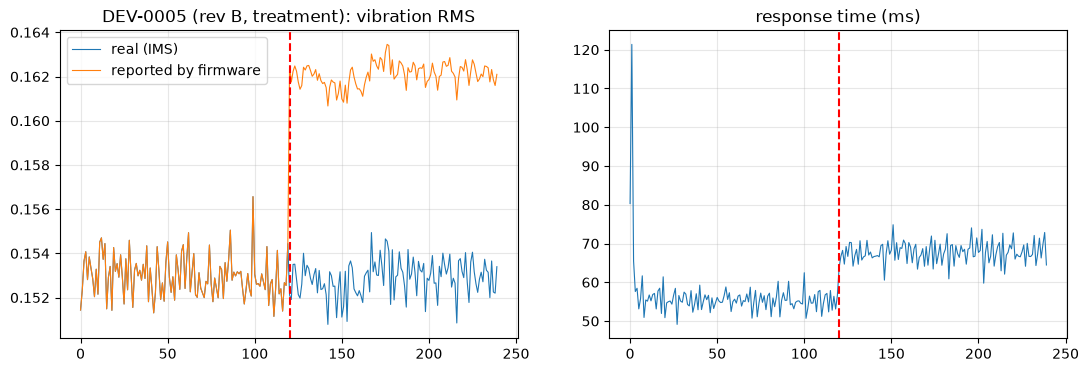

In [7]:
dev = devices[(devices.group == "treatment") & (devices.hw_revision == "B")].device_id.iloc[0]
d = tel[tel.device_id == dev]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(d.interval_idx, d.real_rms, lw=0.8, label="real (IMS)"); ax[0].plot(d.interval_idx, d.vib_rms, lw=0.8, label="reported by firmware")
ax[1].plot(d.interval_idx, d.response_time_ms, lw=0.8)
for a in ax: a.axvline(120, color="red", ls="--")
ax[0].legend(); ax[0].set_title(f"{dev} (rev B, treatment): vibration RMS"); ax[1].set_title("response time (ms)")

**Balance check.** Before rollout the two arms should look the same. Large pre-period differences would point to a
randomisation problem.

In [8]:
from src.performance_metrics import device_period_kpis
from src.statistical_tests import welch_ttest
k = device_period_kpis(tel)
pre = k[k.period == "pre"]
rows = []
for m in ["fw_errors_per_100", "uptime_pct", "mean_rms", "sensor_jitter", "p50_response_ms", "hw_fault_rate_pct"]:
    a, b = pre[pre.group == "control"][m], pre[pre.group == "treatment"][m]
    rows.append({"metric": m, "control": a.mean(), "treatment": b.mean(), "p": welch_ttest(a, b)[1]})
pd.DataFrame(rows)

,metric,control,treatment,p
0,fw_errors_per_100,4.6389,4.2120,0.2505
1,uptime_pct,99.9360,99.4323,0.2884
2,mean_rms,0.0880,0.0872,0.8962
3,sensor_jitter,0.0130,0.0143,0.1637
4,p50_response_ms,44.7075,45.7772,0.1946
5,hw_fault_rate_pct,0.0000,0.9783,0.3020
